# Forecasting Exchange Rates using Time Series Analysis
**ARIMA vs. Exponential Smoothing on the USD → Australian Dollar daily exchange rate (1990 – 2010)**

**Objective:** use ARIMA and Exponential Smoothing models to forecast future exchange rates from `exchange_rate.csv`, and compare them with proper error metrics.

**Notebook outline**
1. Data preparation & exploration (loading, plots, missing values / anomalies, stationarity)
2. ARIMA modelling (ACF/PACF, order selection, fitting, residual diagnostics, forecasting)
3. Exponential Smoothing modelling (SES, Holt, damped Holt)
4. Evaluation & comparison (MAE, RMSE, MAPE, naive benchmark, rolling-origin check)
5. Conclusion

In [1]:
# ---- Imports & global settings ----
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.stats.stattools import jarque_bera
from scipy import stats

warnings.filterwarnings("ignore")          # keep the output readable (convergence / future warnings)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 4.5)
plt.rcParams["axes.titleweight"] = "bold"
SEED = 42
np.random.seed(SEED)

---
## Part 1 – Data Preparation and Exploration
### 1.1 Data loading
The file has two columns: `date` (format `dd-mm-yyyy HH:MM`) and `Ex_rate` (USD to AUD). The dates are day-first, so the format is given **explicitly**; otherwise pandas could silently swap day and month.

In [2]:
df = pd.read_csv("exchange_rate.csv")
df["date"] = pd.to_datetime(df["date"], format="%d-%m-%Y %H:%M")   # explicit day-first parsing
df = df.set_index("date").sort_index()

print("Shape           :", df.shape)
print("Date range      :", df.index.min().date(), "->", df.index.max().date())
print("Data types      :", dict(df.dtypes.astype(str)))
df.head()

Shape           : (7588, 1)
Date range      : 1990-01-01 -> 2010-10-10
Data types      : {'Ex_rate': 'float64'}


,Ex_rate
date,
1990-01-01,0.7855
1990-01-02,0.7818
1990-01-03,0.7867
1990-01-04,0.7860
1990-01-05,0.7849


In [3]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Ex_rate,7588.0,0.776974,0.13662,0.483297,0.701422,0.761377,0.873477,1.102536


### 1.2 Data-quality checks
Before modelling we check for (a) missing values, (b) duplicated timestamps, (c) gaps in the calendar and (d) non-positive values. Time-series models need a regular, gap-free index.

In [4]:
y = df["Ex_rate"]

print("Missing values        :", int(y.isna().sum()))
print("Duplicated timestamps :", int(df.index.duplicated().sum()))
print("Non-positive values   :", int((y <= 0).sum()))

# Compare against a complete daily calendar to detect gaps
full_range = pd.date_range(y.index.min(), y.index.max(), freq="D")
print("Missing calendar days :", len(full_range.difference(y.index)))
print("Step sizes between observations:\n", y.index.to_series().diff().value_counts().to_string())

Missing values        : 0
Duplicated timestamps : 0
Non-positive values   : 0
Missing calendar days : 0
Step sizes between observations:
 date
1 days    7587


The data is already complete: no missing values, duplicates or calendar gaps, with exactly one observation per day (7,588 days). We still set an explicit daily frequency (`asfreq('D')`) and add a forward-fill as a **safety net**, so the code stays robust if the data changes. It is a no-op here.

In [5]:
y = y.asfreq("D")            # explicit daily frequency (required by statsmodels for forecasting dates)
y = y.ffill()                # safety net: no-op on this dataset, since there are no gaps
y.name = "USD/AUD"
print("Frequency:", y.index.freq, "| observations:", len(y))

Frequency: <Day> | observations: 7588


### 1.3 Initial exploration – the raw series

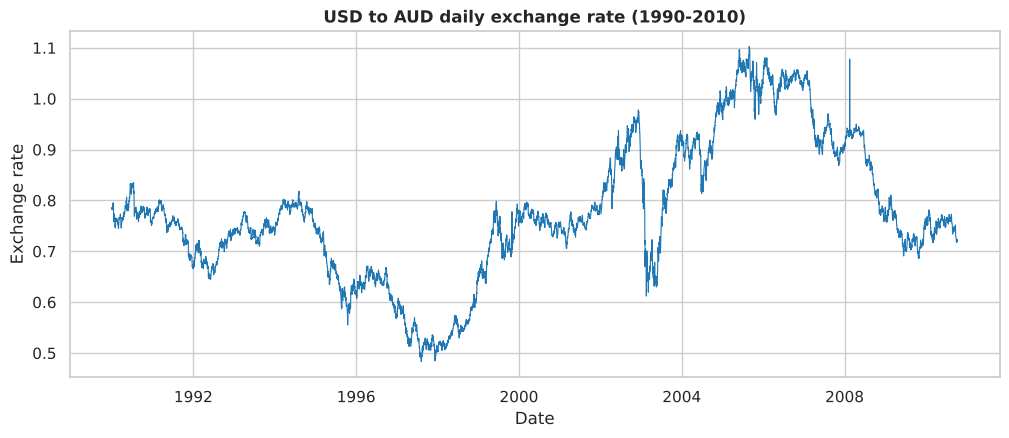

In [6]:
fig, ax = plt.subplots()
ax.plot(y, lw=0.8, color="#1f77b4")
ax.set(title="USD to AUD daily exchange rate (1990-2010)", xlabel="Date", ylabel="Exchange rate")
plt.show()

**Observations**
- There is **no regular seasonal pattern**. The series moves in long, persistent swings (multi-year trends) instead.
- The rate rises, falls, and rises again, so there is **no single global trend**. This is typical of a **random-walk-like (non-stationary)** series.
- The level changes by large amounts over the years, so the mean and variance are not constant.

We now look at the rolling statistics, a decomposition, the distribution and the day-to-day changes.

### 1.4 Anomaly detection and preprocessing
Level plots hide jumps, so we inspect the **daily % changes**. FX returns are naturally fat-tailed, so a large move alone is not an error. A **data glitch**, however, has a distinctive signature: a one-day spike that **reverses the very next day** (price jumps up and falls straight back, or vice versa). Genuine market moves persist, and glitches do not.

Daily % change: std=0.763, min=-13.92, max=16.34
Observations with |z| > 4 (large moves): 36

Single-day spikes detected (value, neighbours):
  1999-10-30: 0.7778   (previous day 0.6979, next day 0.7039)
  2008-02-16: 1.0778   (previous day 0.9264, next day 0.9277)


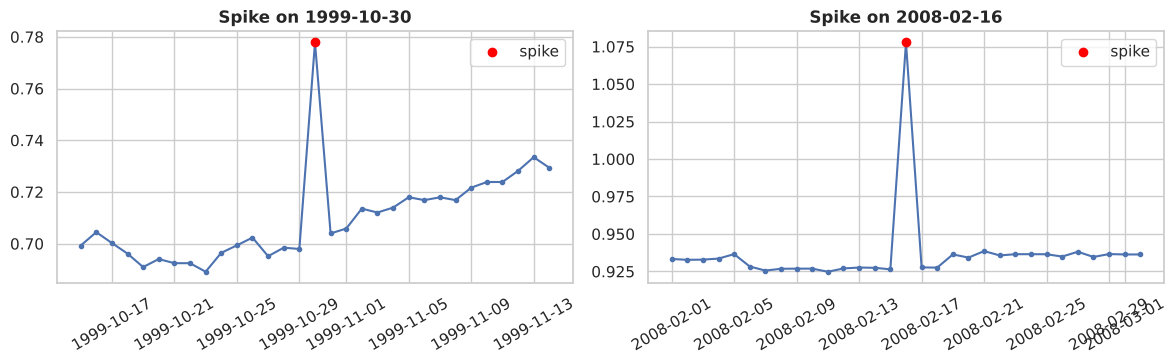

In [7]:
ret = y.pct_change() * 100                                   # daily % change
z = (ret - ret.mean()) / ret.std()
print(f"Daily % change: std={ret.std():.3f}, min={ret.min():.2f}, max={ret.max():.2f}")
print(f"Observations with |z| > 4 (large moves): {(np.abs(z) > 4).sum()}")

# --- Glitch rule: a move > 5% that is undone by an opposite move > 5% on the next day ---
THR = 5.0
spike = (ret.abs() > THR) & (ret.shift(-1).abs() > THR) & (np.sign(ret) != np.sign(ret.shift(-1)))
spike_dates = y.index[spike.fillna(False)]
print("\nSingle-day spikes detected (value, neighbours):")
for d in spike_dates:
    prev, nxt = y.shift(1)[d], y.shift(-1)[d]
    print(f"  {d.date()}: {y[d]:.4f}   (previous day {prev:.4f}, next day {nxt:.4f})")

# Plot the spikes in context
fig, axes = plt.subplots(1, len(spike_dates), figsize=(6 * len(spike_dates), 3.8))
for ax, d in zip(np.atleast_1d(axes), spike_dates):
    w = y[d - pd.Timedelta(days=15): d + pd.Timedelta(days=15)]
    ax.plot(w, marker="o", ms=3); ax.scatter([d], [y[d]], color="red", zorder=5, label="spike")
    ax.set_title(f"Spike on {d.date()}"); ax.legend(); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

The rule isolates **single-day spikes** (e.g. 2008-02-16: 0.926 → 1.078 → 0.928). Such a value cannot be a real market move, because a 16% daily swing that fully reverses within 24 hours does not occur in a major currency pair. These are most likely **data-entry / feed errors**.

**Decision:** treat these points as missing and fill them by **linear interpolation** between their neighbours. They would otherwise distort the model in two ways: they create artificial negative lag-1 autocorrelation (spike up, then down), and they inflate the error variance.

Other large moves (e.g. the persistent move in Feb 2003) are **kept**, since the level stays at the new value afterwards. Those are genuine market moves, and removing them would understate real forecast uncertainty.

Values corrected: 2 | missing after cleaning: 0


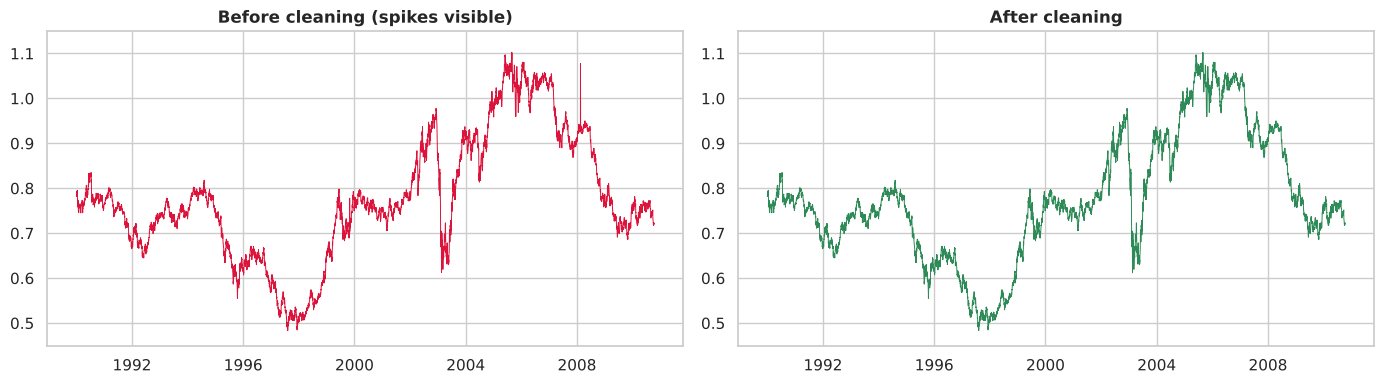

Lag-1 autocorrelation of daily changes  raw: -0.131  |  cleaned: -0.034


In [8]:
y_raw = y.copy()                                            # keep the raw series for before/after comparison
y = y.copy()
y.loc[spike_dates] = np.nan
y = y.interpolate(method="time")                            # linear interpolation in time
print("Values corrected:", len(spike_dates), "| missing after cleaning:", int(y.isna().sum()))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(y_raw, lw=0.7, color="crimson"); ax[0].set_title("Before cleaning (spikes visible)")
ax[1].plot(y, lw=0.7, color="seagreen");   ax[1].set_title("After cleaning")
for a_ in ax: a_.set_ylim(0.45, 1.15)
plt.tight_layout(); plt.show()

# Effect on lag-1 autocorrelation of daily changes
print("Lag-1 autocorrelation of daily changes  raw: %.3f  |  cleaned: %.3f"
      % (y_raw.diff().autocorr(1), y.diff().autocorr(1)))

Cleaned daily % change: std=0.702, min=-10.19, max=6.10
Largest remaining moves:


,pct_change
date,
2003-02-16,-10.185999
2003-02-04,-7.722983
2003-02-06,-7.114224
2003-02-19,6.101220
1995-11-13,4.943095
2003-03-07,-4.869866


Days identical to the previous day: 340 (4.5%); share by weekday (Mon=0): {0: 0.081, 1: 0.025, 2: 0.02, 3: 0.041, 4: 0.03, 5: 0.062, 6: 0.054}


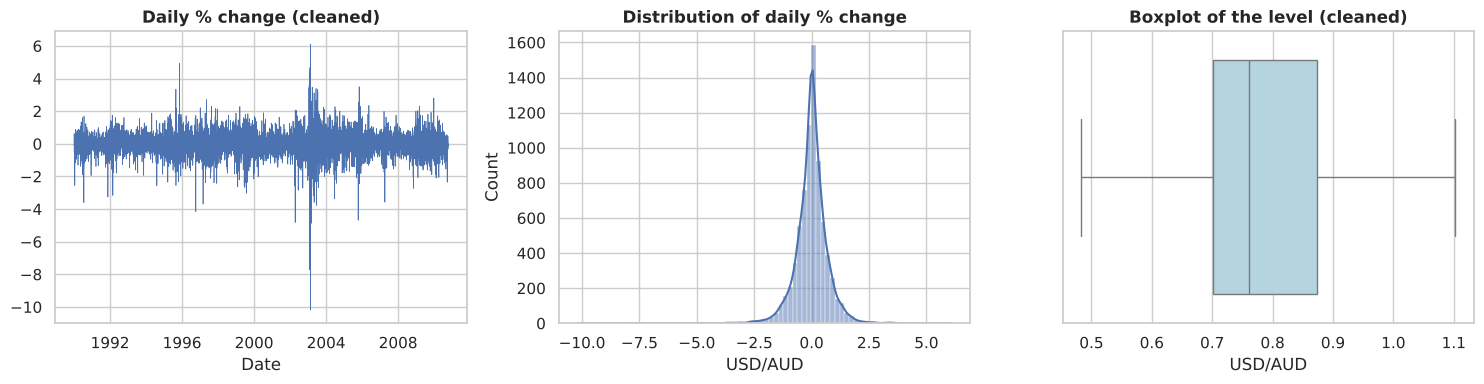

In [9]:
# Remaining large moves and repeated values
ret = y.pct_change().dropna() * 100
print(f"Cleaned daily % change: std={ret.std():.3f}, min={ret.min():.2f}, max={ret.max():.2f}")
print("Largest remaining moves:")
display(ret.reindex(ret.abs().sort_values(ascending=False).index).head(6).to_frame("pct_change"))

same = (y.diff() == 0)
print(f"Days identical to the previous day: {same.sum()} ({same.mean():.1%}); "
      f"share by weekday (Mon=0): {same.groupby(y.index.dayofweek).mean().round(3).to_dict()}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(ret, lw=0.5); axes[0].set(title="Daily % change (cleaned)", xlabel="Date")
sns.histplot(ret, bins=80, kde=True, ax=axes[1]); axes[1].set(title="Distribution of daily % change")
sns.boxplot(x=y, ax=axes[2], color="lightblue"); axes[2].set(title="Boxplot of the level (cleaned)")
plt.tight_layout(); plt.show()

**Findings**
- The remaining large moves are real: the returns show **fat tails and volatility clustering** (calm and turbulent periods alternate), typical for FX.
- Roughly 4-5% of days repeat the previous value. They are spread across all weekdays, so this is not a pure weekend effect. They are stale quotes, which is common in daily FX data, and they are left unchanged.
- The level boxplot shows no extreme outliers, and there are no missing values.

### 1.5 Trend, seasonality and volatility of the cleaned series

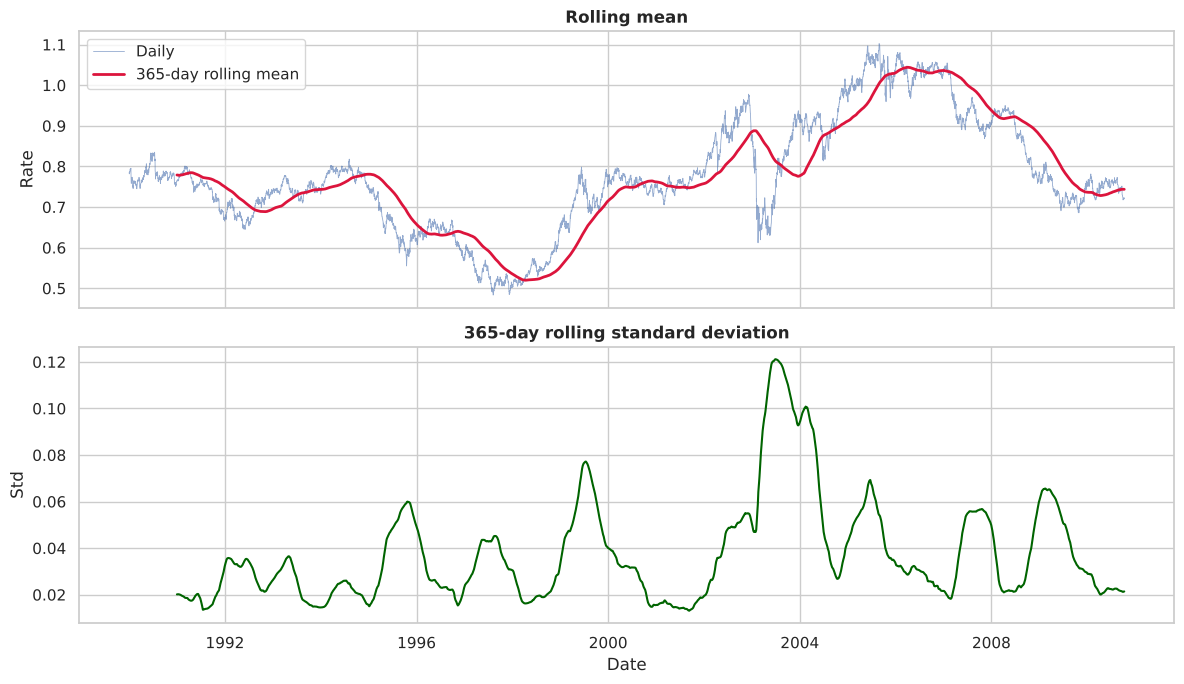

In [10]:
# Rolling mean / std  (window = 365 days ~ one year)
roll_mean = y.rolling(365).mean()
roll_std  = y.rolling(365).std()

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
axes[0].plot(y, lw=0.6, alpha=0.6, label="Daily")
axes[0].plot(roll_mean, color="crimson", lw=2, label="365-day rolling mean")
axes[0].set(title="Rolling mean", ylabel="Rate"); axes[0].legend()
axes[1].plot(roll_std, color="darkgreen", lw=1.5)
axes[1].set(title="365-day rolling standard deviation", ylabel="Std", xlabel="Date")
plt.tight_layout(); plt.show()

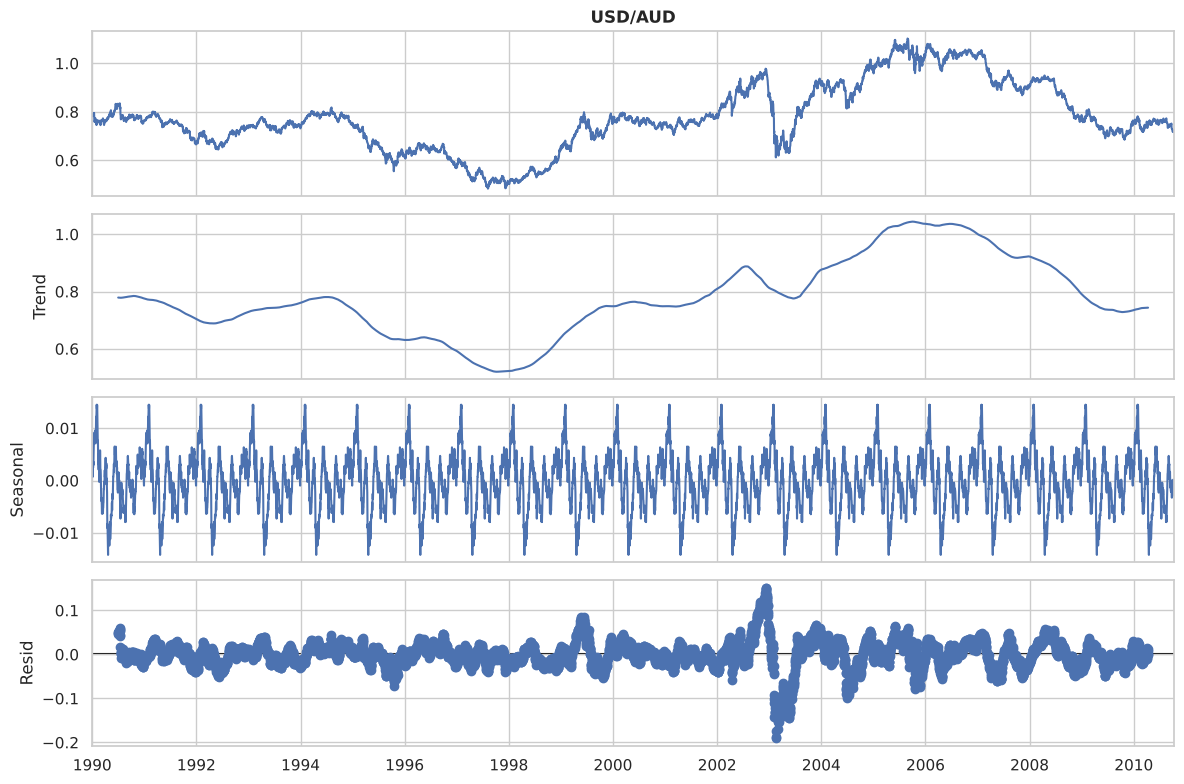

Strength of yearly seasonality: 0.028  (0 = none, 1 = strong)


In [11]:
# Classical decomposition with a yearly period (365 days) to look for trend / seasonality
decomp = seasonal_decompose(y, model="additive", period=365)
fig = decomp.plot(); fig.set_size_inches(12, 8); plt.tight_layout(); plt.show()

# Relative strength of seasonality: 1 - Var(resid) / Var(seasonal + resid)  (Hyndman)
res = decomp.resid.dropna(); seas = decomp.seasonal.loc[res.index]
Fs = max(0, 1 - res.var() / (res + seas).var())
print(f"Strength of yearly seasonality: {Fs:.3f}  (0 = none, 1 = strong)")

The decomposition is dominated by the trend component. The seasonal component is tiny (about ±0.014 around a rate of ~0.78) and its strength score is low, so **yearly seasonality is negligible**. That is why seasonal models are not pursued later.

### 1.6 Stationarity tests
ARIMA needs a stationary series (or one that can be made stationary by differencing). We use two complementary tests:
- **ADF**: H0 = unit root (non-stationary). A small p-value indicates stationarity.
- **KPSS**: H0 = stationary. A small p-value indicates non-stationarity.

In [12]:
def stationarity_report(series, name):
    """Run ADF and KPSS and print a compact summary."""
    adf_stat, adf_p, *_ = adfuller(series.dropna(), autolag="AIC")
    kpss_stat, kpss_p, *_ = kpss(series.dropna(), regression="c", nlags="auto")
    return {"Series": name,
            "ADF stat": round(adf_stat, 3), "ADF p-value": round(adf_p, 4),
            "KPSS stat": round(kpss_stat, 3), "KPSS p-value": round(kpss_p, 4),   # p is clipped to [0.01, 0.10]
            "Verdict": "stationary" if (adf_p < 0.05 and kpss_p > 0.05) else "non-stationary"}

diff1 = y.diff().dropna()
pd.DataFrame([stationarity_report(y, "Level"),
              stationarity_report(diff1, "1st difference")]).set_index("Series")

,ADF stat,ADF p-value,KPSS stat,KPSS p-value,Verdict
Series,,,,,
Level,-1.672,0.4456,5.290,0.01,non-stationary
1st difference,-30.414,0.0000,0.105,0.10,stationary


The **level** series is non-stationary: ADF cannot reject the unit root and KPSS rejects stationarity. After **one difference** both tests agree that the series is stationary. This points to **d = 1**, and a second difference would be unnecessary over-differencing.

### 1.7 Train / test split
Forecasting quality must be judged on data the models have not seen. We hold out the **last 365 days (~1 year)** as the test set and train on everything before it. The same split is used for **all** models, so the comparison is fair.

Train: 1990-01-01 -> 2009-10-10  (7223 obs)
Test : 2009-10-11 -> 2010-10-10  (365 obs)


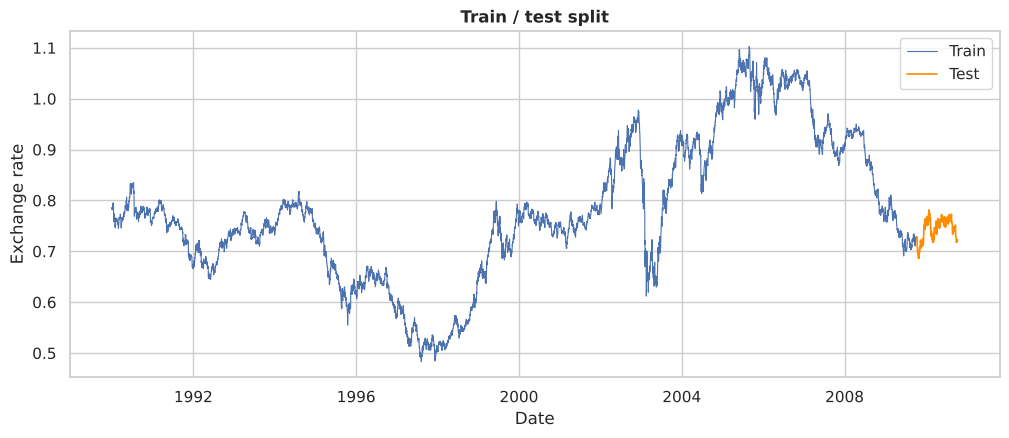

In [13]:
H = 365                                  # forecast horizon = one year of daily data
train, test = y.iloc[:-H], y.iloc[-H:]
print(f"Train: {train.index.min().date()} -> {train.index.max().date()}  ({len(train)} obs)")
print(f"Test : {test.index.min().date()} -> {test.index.max().date()}  ({len(test)} obs)")

fig, ax = plt.subplots()
ax.plot(train, label="Train", lw=0.8); ax.plot(test, label="Test", color="darkorange", lw=1.2)
ax.set(title="Train / test split", xlabel="Date", ylabel="Exchange rate"); ax.legend(); plt.show()

---
## Part 2 – Model Building: ARIMA
### 2.1 Parameter selection with ACF and PACF
`ARIMA(p, d, q)`: **d** is the number of differences (found above, d = 1), **p** is the autoregressive order (read from the PACF cut-off) and **q** is the moving-average order (read from the ACF cut-off). All plots use the **training data only**, to avoid leaking test information into model selection.

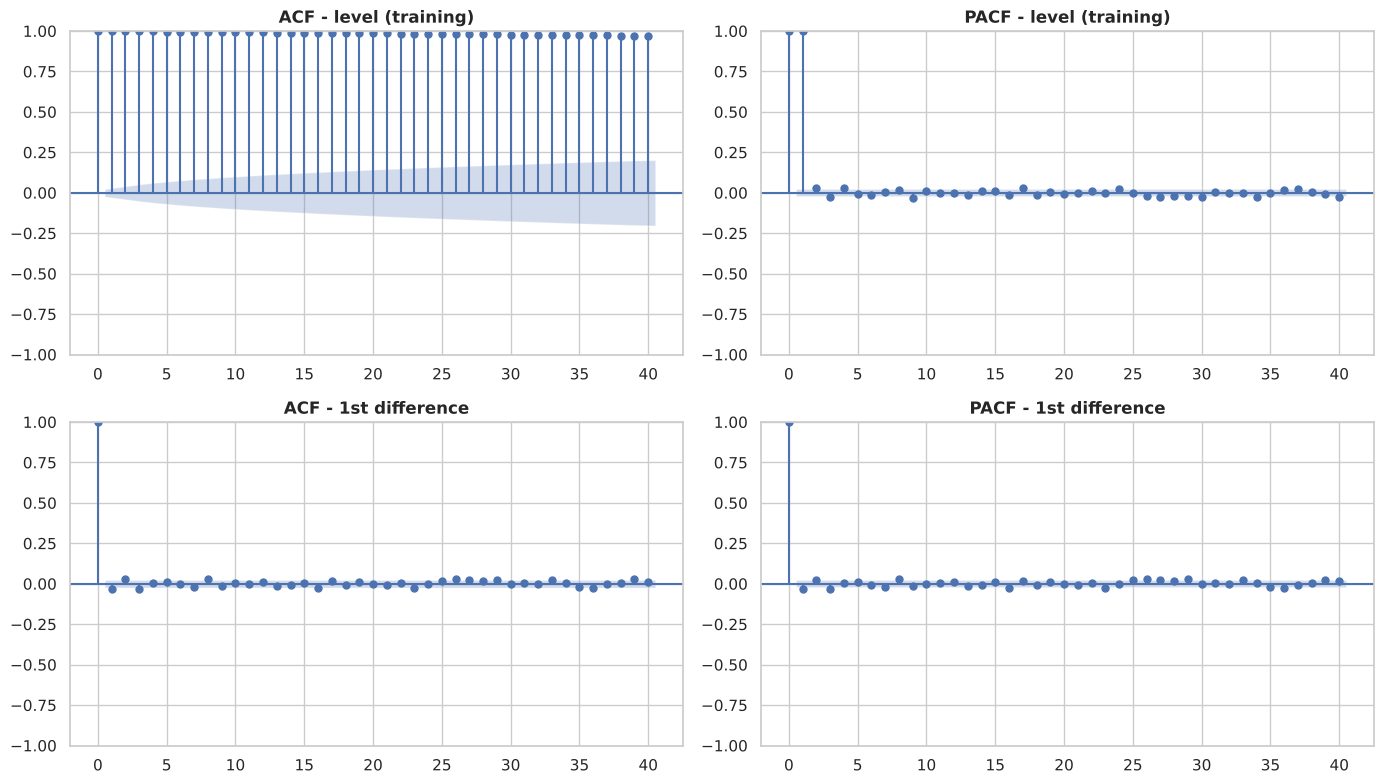

In [14]:
train_diff = train.diff().dropna()

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
plot_acf(train,       lags=40, ax=axes[0, 0], title="ACF - level (training)")
plot_pacf(train,      lags=40, ax=axes[0, 1], title="PACF - level (training)", method="ywm")
plot_acf(train_diff,  lags=40, ax=axes[1, 0], title="ACF - 1st difference")
plot_pacf(train_diff, lags=40, ax=axes[1, 1], title="PACF - 1st difference", method="ywm")
plt.tight_layout(); plt.show()

**Reading the plots**
- **Level:** the ACF decays very slowly (values near 1 for many lags) and the PACF has a single dominant spike at lag 1. This is the classic **unit-root / random-walk** signature and confirms the need for differencing (**d = 1**).
- **First difference:** the autocorrelations are tiny. Lags 1 and 3 are only just outside the ±1.96/√n ≈ ±0.023 band (r ≈ -0.03), and almost everything else is inside it. With more than 7,000 observations even such small values are statistically significant, but they are practically negligible. The differenced series is therefore **very close to white noise**.

This suggests a very low-order model: **ARIMA(0,1,0)** (random walk) as the baseline, and small ARIMA(p,1,q) variants with p, q ≤ 3 (the lags where the small spikes appear) as candidates. Rather than relying on visual reading alone, we also run a **grid search over p, q ∈ {0,…,3} with d = 1**. Models are ranked by **AIC/BIC** (information criteria that penalise complexity), and their residuals are checked with a Ljung-Box test.

In [15]:
# ---- Grid search over (p, 1, q), fitted on the training set only ----
rows = []
for p in range(4):
    for q in range(4):
        try:
            m = ARIMA(train, order=(p, 1, q)).fit()
            lb30 = acorr_ljungbox(m.resid.iloc[1:], lags=[30], return_df=True)["lb_pvalue"].iloc[0]
            rows.append({"order": (p, 1, q), "AIC": m.aic, "BIC": m.bic, "LjungBox_p(30)": lb30})
        except Exception as e:                                  # skip non-convergent combinations
            rows.append({"order": (p, 1, q), "AIC": np.nan, "BIC": np.nan, "LjungBox_p(30)": np.nan})

grid = pd.DataFrame(rows).dropna().sort_values("AIC").reset_index(drop=True)
print("Top 8 by AIC:")
display(grid.head(8).round(4))
print("Top 6 by BIC:")
display(grid.sort_values("BIC").head(6).round(4))

Top 8 by AIC:


,order,AIC,BIC,LjungBox_p(30)
0,"(3, 1, 3)",-54871.8838,-54823.6896,0.1506
1,"(2, 1, 3)",-54871.8202,-54830.5109,0.1040
2,"(3, 1, 2)",-54868.7315,-54827.4222,0.0590
3,"(0, 1, 3)",-54868.1541,-54840.6145,0.0221
4,"(3, 1, 0)",-54867.9455,-54840.4059,0.0209
5,"(1, 1, 3)",-54866.3199,-54831.8954,0.0230
6,"(3, 1, 1)",-54865.9145,-54831.4901,0.0208
7,"(1, 1, 2)",-54865.5912,-54838.0517,0.0128


Top 6 by BIC:


,order,AIC,BIC,LjungBox_p(30)
13,"(0, 1, 0)",-54855.0040,-54848.1191,0.0001
11,"(1, 1, 0)",-54860.3230,-54846.5532,0.0011
12,"(0, 1, 1)",-54859.9672,-54846.1975,0.0009
9,"(2, 1, 0)",-54863.1975,-54842.5428,0.0047
10,"(0, 1, 2)",-54862.4194,-54841.7647,0.0038
3,"(0, 1, 3)",-54868.1541,-54840.6145,0.0221


In [16]:
best_aic = grid.sort_values("AIC").iloc[0]["order"]
best_bic = grid.sort_values("BIC").iloc[0]["order"]

# Selection rule: lowest BIC among models whose residuals pass the Ljung-Box white-noise test (p > 0.05 at lag 30)
adequate = grid[grid["LjungBox_p(30)"] > 0.05].sort_values("BIC")
best_adequate = adequate.iloc[0]["order"]
print("Best by AIC                     :", best_aic)
print("Best by BIC                     :", best_bic)
print("Best BIC with white-noise resid :", best_adequate)

Best by AIC                     : (3, 1, 3)
Best by BIC                     : (0, 1, 0)
Best BIC with white-noise resid : (2, 1, 3)


**Choosing the order.** The three criteria point to different models, which is itself informative:
- **BIC picks ARIMA(0,1,0)**, the pure random walk. BIC penalises complexity heavily, and after cleaning, the differenced series is almost white noise (lag-1 autocorrelation ≈ -0.03).
- **AIC picks ARIMA(3,1,3)**, a much richer model whose AIC gain over the random walk is only about 17 points on 7,000+ observations.
- **Residual check:** with this much data even tiny autocorrelations are statistically significant. The random walk and the small AR/MA models fail the Ljung-Box test at lag 30, while the larger models pass it.

To balance parsimony and adequacy we use the rule *"lowest BIC among models with white-noise residuals"*. This gives our **primary model, ARIMA(2,1,3)**. The random walk (BIC-best) and the AIC-best model are kept as comparators in the test-set evaluation. Statistical fit and forecast accuracy are not the same thing, so we check both.

### 2.2 Model fitting

In [17]:
cand_orders = {
    "ARIMA primary (BIC + white-noise resid)": best_adequate,
    "ARIMA AIC-best": best_aic,
    "ARIMA BIC-best / random walk": best_bic,
}
# de-duplicate if the same order appears twice
arima_models, seen = {}, {}
for name, order in cand_orders.items():
    key = tuple(order)
    if key in seen:
        print(f"{name}: same order {key} as '{seen[key]}', reusing the fit")
        arima_models[name] = arima_models[seen[key]]; continue
    seen[key] = name
    arima_models[name] = ARIMA(train, order=key).fit()

primary_name = "ARIMA primary (BIC + white-noise resid)"
arima = arima_models[primary_name]
print("\nPrimary model:", primary_name, tuple(best_adequate))
print(arima.summary())


Primary model: ARIMA primary (BIC + white-noise resid) (2, 1, 3)
                               SARIMAX Results                                
Dep. Variable:                USD/AUD   No. Observations:                 7223
Model:                 ARIMA(2, 1, 3)   Log Likelihood               27441.910
Date:                Tue, 13 Oct 2026   AIC                         -54871.820
Time:                        08:47:18   BIC                         -54830.511
Sample:                    01-01-1990   HQIC                        -54857.608
                         - 10-10-2009                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.6350      0.099     -6.413      0.000      -0.829      -0.441
ar.L2         -0.6686      0.086     -7.800      0.000      -0.83

### 2.3 Residual diagnostics
A well-specified model leaves residuals that behave like **white noise**: zero mean, no autocorrelation, constant variance and (ideally) a normal distribution. We check these with plots and formal tests (Ljung-Box for autocorrelation, Jarque-Bera for normality).

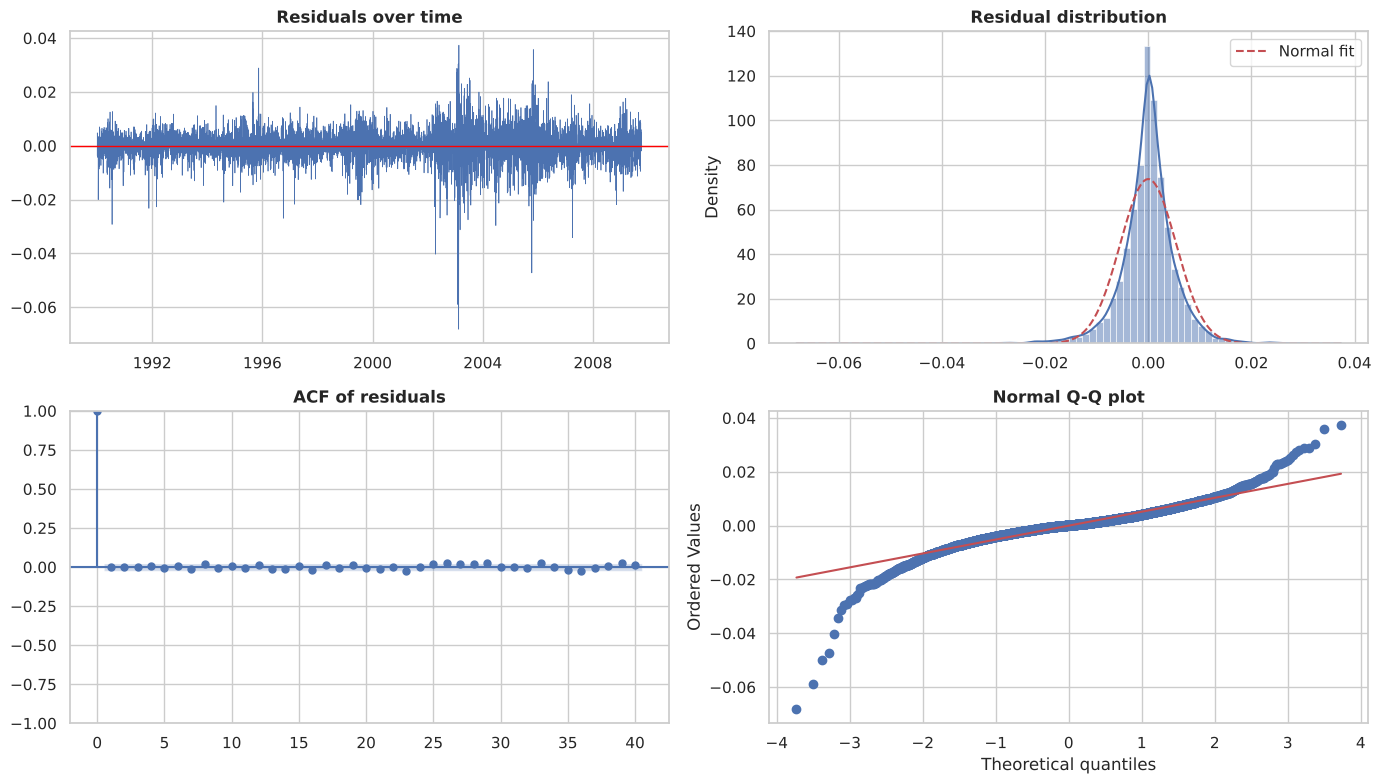

Ljung-Box test (H0: no autocorrelation in residuals)


,lb_stat,lb_pvalue
10,5.5830,0.8490
20,14.6389,0.7967
30,40.0436,0.1040


Jarque-Bera: stat=38798.3, p=0, skew=-0.87, kurtosis=14.22
Residual mean = -0.000008, std = 0.00541

Ljung-Box on SQUARED residuals (H0: no ARCH effect)


,lb_stat,lb_pvalue
10,2058.3251,0.0
20,3727.8241,0.0


In [18]:
resid = arima.resid.iloc[1:]          # drop the first residual (distorted by the differencing initialisation)

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes[0, 0].plot(resid, lw=0.5); axes[0, 0].axhline(0, color="red", lw=1)
axes[0, 0].set(title="Residuals over time")
sns.histplot(resid, bins=80, kde=True, stat="density", ax=axes[0, 1])
xs = np.linspace(resid.min(), resid.max(), 300)
axes[0, 1].plot(xs, stats.norm.pdf(xs, resid.mean(), resid.std()), "r--", label="Normal fit")
axes[0, 1].set(title="Residual distribution"); axes[0, 1].legend()
plot_acf(resid, lags=40, ax=axes[1, 0], title="ACF of residuals")
stats.probplot(resid, dist="norm", plot=axes[1, 1]); axes[1, 1].set_title("Normal Q-Q plot")
plt.tight_layout(); plt.show()

# Formal tests
lb = acorr_ljungbox(resid, lags=[10, 20, 30], return_df=True)
jb_stat, jb_p, skew, kurt = jarque_bera(resid)
print("Ljung-Box test (H0: no autocorrelation in residuals)")
display(lb.round(4))
print(f"Jarque-Bera: stat={jb_stat:.1f}, p={jb_p:.4g}, skew={skew:.2f}, kurtosis={kurt:.2f}")
print(f"Residual mean = {resid.mean():.6f}, std = {resid.std():.5f}")

# Volatility clustering check: autocorrelation of squared residuals
lb2 = acorr_ljungbox(resid**2, lags=[10, 20], return_df=True)
print("\nLjung-Box on SQUARED residuals (H0: no ARCH effect)")
display(lb2.round(4))

**Interpretation**
- **Mean ≈ 0, no autocorrelation:** the residual mean is about 0, and the ACF stays inside the band. The Ljung-Box p-values are large (0.85, 0.80 and 0.10 at lags 10, 20 and 30), so there is **no significant remaining linear structure**. The model has extracted the linear information available in the past values.
- **Non-normality:** the Q-Q plot and the Jarque-Bera test show **heavy tails** (kurtosis ≈ 14) and some negative skew, mostly from the large Feb-2003 moves. This is expected for FX data.
- **Volatility clustering:** the squared residuals are strongly autocorrelated (ARCH effect), so calm and turbulent periods alternate and the **variance is not constant**. This does not bias the point forecast, but the **constant-width prediction intervals are only approximate**. A GARCH-type model would be the natural extension for the intervals; it is beyond the scope of this assignment.
- **Parsimony warning:** the AR and MA coefficients of the (2,1,3) model are large and of opposite sign (≈ ∓0.6), meaning they nearly cancel each other. The model is only slightly better than a random walk, which we verify on the test set.

Overall the **mean model is adequate**, and the remaining weakness (changing volatility) is a variance issue, not a mean issue.

### 2.4 Out-of-sample forecasting (ARIMA)

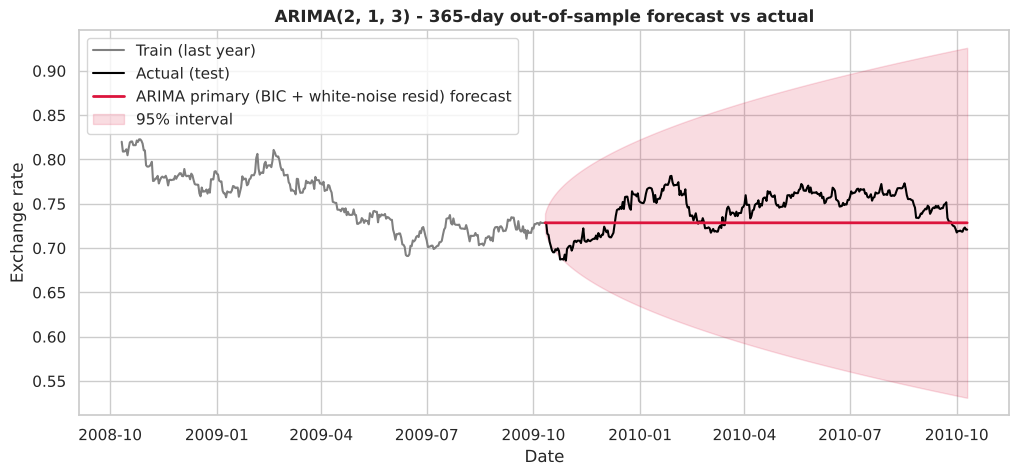

In [19]:
def forecast_with_ci(fitted, steps, alpha=0.05):
    """Return point forecast and CI as aligned DataFrame for a fitted ARIMA result."""
    fc = fitted.get_forecast(steps=steps)
    out = fc.predicted_mean.to_frame("forecast")
    ci = fc.conf_int(alpha=alpha); ci.columns = ["lower", "upper"]
    return out.join(ci)

arima_fc = forecast_with_ci(arima, H)
arima_fc.index = test.index                      # align to test dates

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(train.iloc[-365:], label="Train (last year)", color="gray")
ax.plot(test, label="Actual (test)", color="black")
ax.plot(arima_fc["forecast"], label=f"{primary_name} forecast", color="crimson", lw=2)
ax.fill_between(arima_fc.index, arima_fc["lower"], arima_fc["upper"], color="crimson", alpha=0.15, label="95% interval")
ax.set(title=f"ARIMA{tuple(best_adequate)} - {H}-day out-of-sample forecast vs actual", xlabel="Date", ylabel="Exchange rate")
ax.legend(); plt.show()

With d = 1 and a (near-)zero drift, the ARIMA forecast is almost a **flat line extending the last observed value**, and the interval widens with the square root of the horizon. This is the correct behaviour for a random-walk-type series: past changes carry (almost) no information about future changes. Next we build the exponential smoothing models for comparison.

---
## Part 3 – Model Building: Exponential Smoothing
Exponential smoothing forecasts as a weighted average of past observations with exponentially decaying weights. We fit three members of the family on the same training data:

| Model | Components | When appropriate |
|---|---|---|
| **SES** | level only | no trend, no seasonality |
| **Holt (additive trend)** | level + linear trend | a persistent trend |
| **Damped Holt** | level + damped trend | a trend that flattens out over the horizon |

A **seasonal Holt-Winters** variant is deliberately not used. The decomposition showed negligible yearly seasonality, and a 365-period seasonal state on this dataset would add hundreds of parameters, which invites over-fitting. Smoothing parameters are estimated by maximum likelihood (`optimized=True`), so we do not choose them by hand.

In [20]:
es_specs = {
    "SES":         dict(trend=None),
    "Holt":        dict(trend="add", damped_trend=False),
    "Damped Holt": dict(trend="add", damped_trend=True),
}
es_models, es_rows = {}, []
for name, spec in es_specs.items():
    m = ExponentialSmoothing(train, initialization_method="estimated", **spec).fit(optimized=True)
    es_models[name] = m
    p = m.params
    es_rows.append({"Model": name, "alpha (level)": p["smoothing_level"],
                    "beta (trend)": p.get("smoothing_trend", np.nan),
                    "phi (damping)": p.get("damping_trend", np.nan),
                    "AIC": m.aic, "BIC": m.bic})
pd.DataFrame(es_rows).set_index("Model").round(5)

,alpha (level),beta (trend),phi (damping),AIC,BIC
Model,,,,,
SES,0.96969,NaN,NaN,-75366.55134,-75352.78129
Holt,0.94884,0.00008,NaN,-75358.35670,-75330.81659
Damped Holt,0.96730,0.00241,0.97489,-75361.73576,-75327.31063


The estimated **alpha is ≈ 0.95 – 0.97** for all models. The level is updated almost entirely from the **most recent observation**, which is again the random-walk behaviour we saw with ARIMA. The trend smoothing parameter beta is essentially 0, meaning the slope changes extremely slowly.

*Note:* the AIC/BIC values of the exponential-smoothing models are computed on a different likelihood basis from those of ARIMA (different initialisation and conditioning), so they are **not comparable across the two families**. Inside the ES family the information criteria prefer SES, but we compare **across** families only on out-of-sample forecast errors.

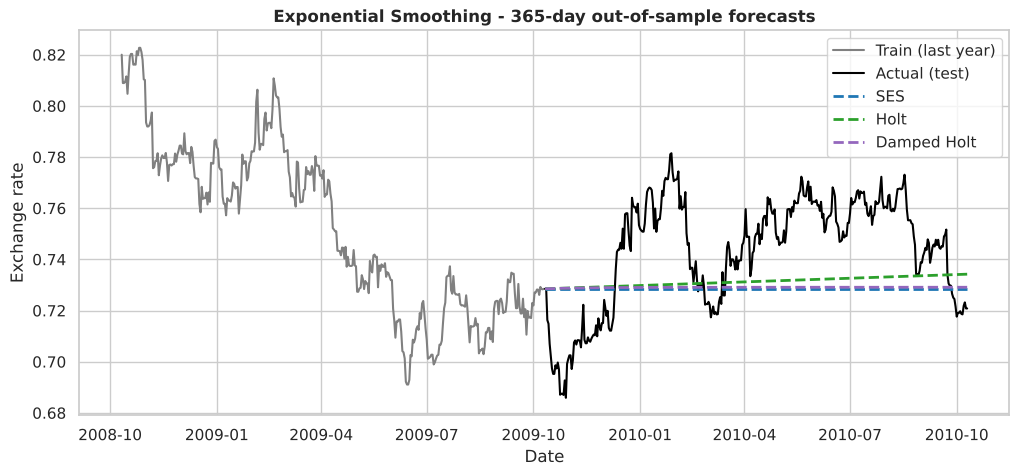

In [21]:
es_fc = {name: m.forecast(H) for name, m in es_models.items()}
for s in es_fc.values(): s.index = test.index

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(train.iloc[-365:], color="gray", label="Train (last year)")
ax.plot(test, color="black", lw=1.5, label="Actual (test)")
for (name, s), c in zip(es_fc.items(), ["tab:blue", "tab:green", "tab:purple"]):
    ax.plot(s, label=name, color=c, lw=2, ls="--")
ax.set(title="Exponential Smoothing - 365-day out-of-sample forecasts", xlabel="Date", ylabel="Exchange rate")
ax.legend(); plt.show()

---
## Part 4 – Evaluation and Comparison
### 4.1 Error metrics
- **MAE** – average absolute error, in the units of the rate.
- **RMSE** – penalises large errors more heavily.
- **MAPE** – average percentage error, which is scale-free and easy to communicate.

A **naive (last-value) forecast** is added as a benchmark. For a random-walk-type series, any model that cannot beat it adds no value.

In [22]:
def mae(a, f):  return float(np.mean(np.abs(a - f)))
def rmse(a, f): return float(np.sqrt(np.mean((a - f) ** 2)))
def mape(a, f): return float(np.mean(np.abs((a - f) / a)) * 100)

naive = pd.Series(train.iloc[-1], index=test.index)       # repeat the last training value

forecasts = {"Naive (last value)": naive}
for name, m in arima_models.items():
    forecasts[name + f" {m.model.order}"] = m.get_forecast(H).predicted_mean.set_axis(test.index)
for name, s in es_fc.items():
    forecasts["ES - " + name] = s

metrics = pd.DataFrame({k: {"MAE": mae(test, v), "RMSE": rmse(test, v), "MAPE (%)": mape(test, v)}
                        for k, v in forecasts.items()}).T
metrics = metrics.sort_values("RMSE")
display(metrics.round(5).style.background_gradient(cmap="Greens_r", subset=["MAE", "RMSE", "MAPE (%)"]))

,MAE,RMSE,MAPE (%)
ES - Holt,0.021410,0.024070,2.863590
ES - Damped Holt,0.023030,0.025830,3.076350
"ARIMA AIC-best (3, 1, 3)",0.023350,0.026190,3.117820
"ARIMA primary (BIC + white-noise resid) (2, 1, 3)",0.023360,0.026200,3.118720
"ARIMA BIC-best / random walk (0, 1, 0)",0.023380,0.026220,3.120950
Naive (last value),0.023380,0.026220,3.120950
ES - SES,0.023380,0.026220,3.121310


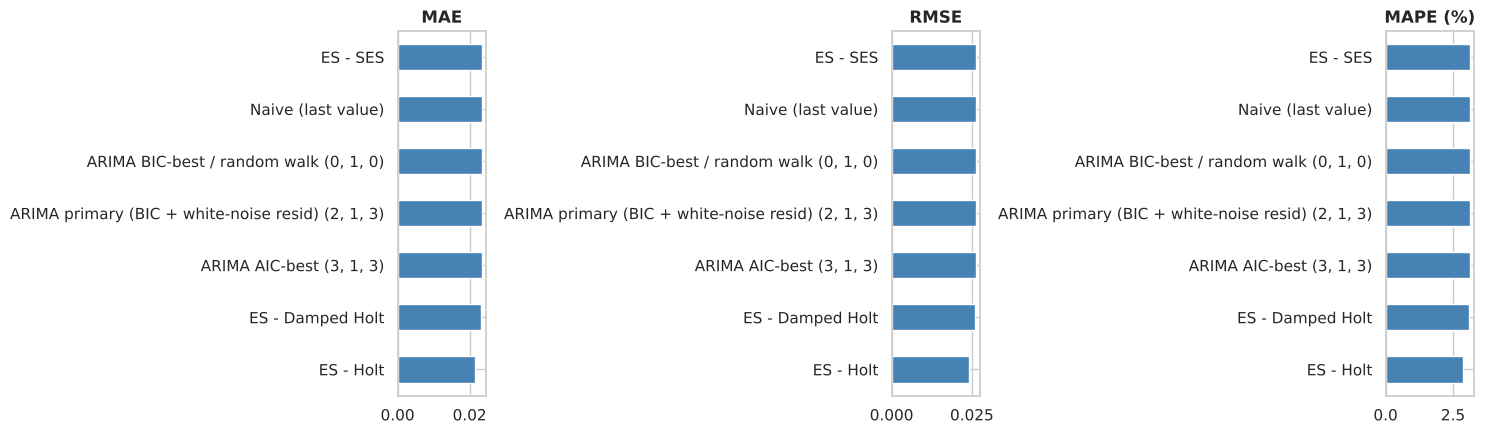

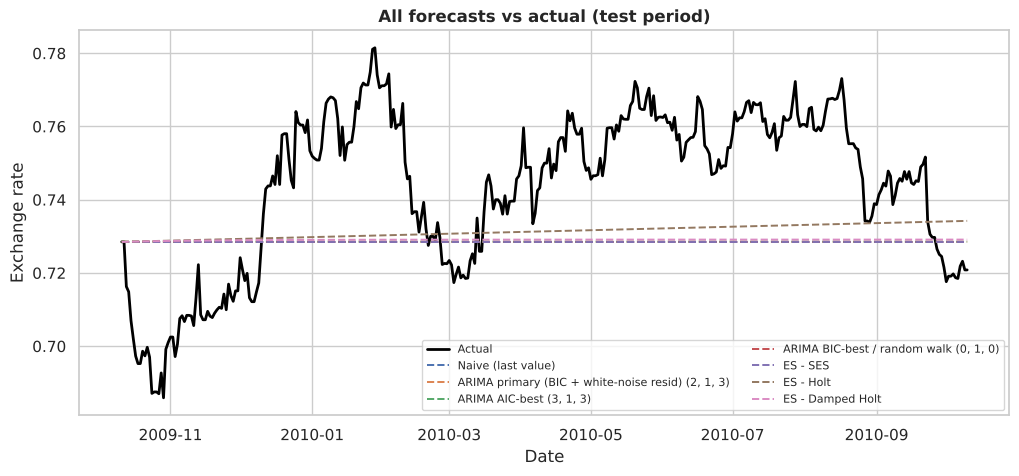

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, col in zip(axes, ["MAE", "RMSE", "MAPE (%)"]):
    metrics[col].sort_values().plot.barh(ax=ax, color="steelblue")
    ax.set_title(col); ax.set_ylabel("")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(test, color="black", lw=2, label="Actual")
for name, s in forecasts.items():
    ax.plot(s, lw=1.4, ls="--", label=name)
ax.set(title="All forecasts vs actual (test period)", xlabel="Date", ylabel="Exchange rate")
ax.legend(fontsize=8, ncol=2); plt.show()

### 4.2 Robustness check – rolling-origin evaluation
A single 365-day test window is only one realisation of a random-like process, so the winner on that window may be partly luck. To check, we repeat the evaluation from **several different forecast origins** (expanding window): at each origin we re-fit each model on all earlier data and forecast the next 90 days. The model orders are held fixed, so the check stays fast.

In [24]:
HORIZON, N_ORIGINS = 90, 12
origins = np.linspace(len(y) - 8 * 365, len(y) - HORIZON, N_ORIGINS).astype(int)   # origins spread over the last ~8 years

arima_order = tuple(best_adequate)
roll = {k: [] for k in ["Naive", f"ARIMA{arima_order}", "ES - SES", "ES - Holt", "ES - Damped Holt"]}

for o in origins:
    tr, te = y.iloc[:o], y.iloc[o:o + HORIZON]
    preds = {"Naive": pd.Series(tr.iloc[-1], index=te.index),
             f"ARIMA{arima_order}": ARIMA(tr, order=arima_order).fit().forecast(HORIZON)}
    for name, spec in es_specs.items():
        preds["ES - " + name] = ExponentialSmoothing(tr, initialization_method="estimated", **spec).fit().forecast(HORIZON)
    for k, p in preds.items():
        roll[k].append({"MAE": mae(te, p.values), "RMSE": rmse(te, p.values), "MAPE": mape(te, p.values)})

roll_summary = pd.DataFrame({k: pd.DataFrame(v).mean() for k, v in roll.items()}).T.sort_values("RMSE")
roll_summary.columns = ["MAE", "RMSE", "MAPE (%)"]
print(f"Mean error over {N_ORIGINS} rolling origins ({HORIZON}-day horizon)")
display(roll_summary.round(5))

Mean error over 12 rolling origins (90-day horizon)


,MAE,RMSE,MAPE (%)
ES - SES,0.03473,0.04103,4.00704
Naive,0.03473,0.04104,4.00711
"ARIMA(2, 1, 3)",0.03481,0.04112,4.01623
ES - Holt,0.03495,0.04135,4.03308
ES - Damped Holt,0.03521,0.04153,4.06014


### 4.3 Final forecast
Using the selected model, we re-fit on the **full** dataset and forecast the next 90 days beyond the end of the data, with a 95% interval.

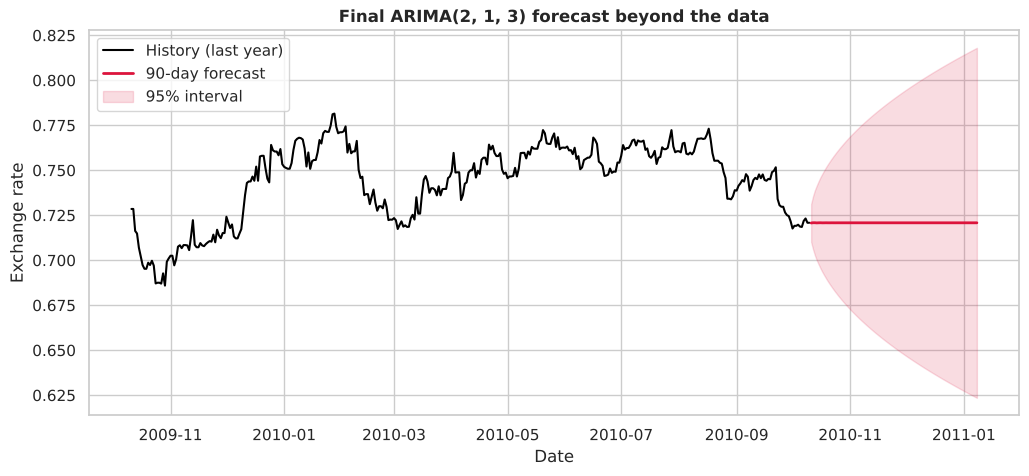

,forecast,lower,upper
2010-10-11,0.7207,0.7102,0.7312
2010-11-09,0.7208,0.6646,0.7770
2010-12-09,0.7208,0.6414,0.8002
2011-01-08,0.7208,0.6235,0.8181


In [25]:
final = ARIMA(y, order=arima_order).fit()
fut = forecast_with_ci(final, 90)
fut.index = pd.date_range(y.index[-1] + pd.Timedelta(days=1), periods=90, freq="D")

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(y.iloc[-365:], color="black", label="History (last year)")
ax.plot(fut["forecast"], color="crimson", lw=2, label="90-day forecast")
ax.fill_between(fut.index, fut["lower"], fut["upper"], color="crimson", alpha=0.15, label="95% interval")
ax.set(title=f"Final ARIMA{arima_order} forecast beyond the data", xlabel="Date", ylabel="Exchange rate")
ax.legend(); plt.show()
fut.iloc[[0, 29, 59, 89]].round(4)

### 4.4 Model comparison and discussion

**Single hold-out (365 days).** The table in 4.1 shows:
- **ARIMA (all three orders), SES and the naive forecast are practically identical** (MAE ≈ 0.0234, RMSE ≈ 0.0262, MAPE ≈ 3.12%). With d = 1 and no drift they all produce an almost **flat forecast at the last observed value**. The extra AR/MA terms of the larger ARIMA models give gains of only the 4th decimal place.
- **Holt (linear trend)** has the lowest error on this particular window (RMSE ≈ 0.0241, about 8% below the naive forecast), with damped Holt second. Its fitted slope is tiny but slightly **positive**, and the actual rate spent most of the test year **above** the last training value (≈ 0.7285), so the gently rising line happened to sit closer to the data than a flat line. This is a small, fortunate alignment, not evidence that the trend was predicted.

**Robustness check (12 rolling origins, 90-day horizon).** The ranking changes. SES, naive and ARIMA are again equal (RMSE ≈ 0.0410), while **Holt and damped Holt are slightly worse** (0.0414 and 0.0415). The trend models only win when the recent trend continues, and they lose when it reverses, so the single-window advantage of Holt is **not a reliable, repeatable edge**.

| | ARIMA | Exponential smoothing |
|---|---|---|
| **Strengths** | Principled order selection (ACF/PACF, AIC/BIC); full residual diagnostics; explicit prediction intervals; handles autocorrelated short-term dynamics | Simple, fast, few parameters; easy to explain; Holt variants capture a local trend |
| **Limitations** | With d = 1 and no drift the forecast is flat and gives no directional information; richer orders add parameters but almost no accuracy; assumes constant variance (violated here: ARCH effect) | Needs a stable local trend to help; trend extrapolation is risky on a random-walk series; SES is effectively the naive forecast (alpha ≈ 0.97); intervals are less standard |
| **Shared** | Neither captures volatility clustering, nor can they predict regime shifts or news-driven jumps | |

---
## Part 5 – Conclusion

**Data.** The daily USD/AUD series (1990 – 2010, 7,588 observations) had no missing values, but contained **two single-day data glitches** (1999-10-30 and 2008-02-16) that were detected as spikes reversing within a day and corrected by interpolation. Cleaning matters: it reduced the lag-1 autocorrelation of daily changes from -0.13 to -0.03 and prevented a spurious AR(1) structure from being modelled. The series is **non-stationary in levels** (ADF / KPSS), **stationary after one difference (d = 1)**, and has **negligible seasonality**.

**Models.**
- **ARIMA:** ACF/PACF showed a differenced series that is almost white noise. The grid search with a white-noise-residual rule selected **ARIMA(2,1,3)**, whose residuals pass the Ljung-Box test. The residuals are heavy-tailed and show **volatility clustering**, so prediction intervals are only approximate.
- **Exponential smoothing:** SES, Holt and damped Holt all estimated α ≈ 0.95 – 0.97, again behaving like a random walk.

**Performance.**
- On the 365-day hold-out, ARIMA, SES and the naive forecast are **equally accurate** (RMSE ≈ 0.0262, MAPE ≈ 3.1%). **Holt was best on this one window** (RMSE ≈ 0.0241, MAPE ≈ 2.9%).
- Across 12 rolling forecast origins the trend models were slightly **worse than the naive forecast**, while SES and ARIMA matched it. Holt's single-window win therefore looks like a lucky trend continuation rather than a lasting advantage.

**Insight and recommendation.** The exchange rate behaves like a **random walk with changing volatility**: past values give essentially no edge over "tomorrow = today". **No model beat the naive benchmark in a repeatable way**. If a simple, defensible forecast is needed, use **ARIMA (or SES)**, which are as accurate as any alternative, come with diagnostics and prediction intervals, and do not rely on trend extrapolation. Holt or damped Holt can be used when there is an external reason to expect a persistent trend, with the understanding that they carry extra risk when trends reverse.

**Limitations and next steps.** (1) Only one currency pair was analysed. (2) The constant-variance assumption is violated, so a **GARCH** model for the variance would give better intervals. (3) Forecasting returns with exogenous drivers (interest-rate differentials, commodity prices) is the most promising route to beating the random walk. (4) Errors are scale-dependent in level terms, and MAPE is only meaningful because the rate is far from zero.